# Mathematics: Matrix Calculus and Automatic Differentiation from Scratch

> **Who is this for:** a beginner who has finished [`02_calculus.ipynb`](02_calculus.ipynb) and wants to know *exactly* how `loss.backward()` works, or a university student revising matrix calculus and backpropagation for an ML exam or an ML-engineering interview.
>
> **What you will learn**
> - **Shapes-first matrix calculus**: gradients, Jacobians and the **numerator-layout** convention, used consistently
> - The key identities, derived with differentials and **checked numerically**: $\nabla(a^\top x)$, $\nabla(x^\top Ax)$, $\nabla\|Ax - b\|^2$, $\nabla \operatorname{tr}(AB)$, $\nabla \log\det X$, the **softmax Jacobian** and the **softmax + cross-entropy gradient**
> - **Jacobian-vector products (JVPs)** vs **vector-Jacobian products (VJPs)**, and why **reverse mode** wins for training
> - **Forward-mode autodiff** with **dual numbers** (a small `Dual` class)
> - **Reverse-mode autodiff**: a micrograd-style scalar `Value` engine with a computational graph and topological sort, then a vectorised `Tensor` engine with `matmul`, broadcasting, `sum`, `relu` and a fused cross-entropy
> - **Gradient checking** done properly: relative error, float64, and kinks
> - Training **logistic regression** and a **2-layer MLP** with our engine, matching PyTorch's gradients
> - **Hessian-vector products** by double backward, and a **Newton (Hessian-free) step**
>
> **Prerequisites:** [`02_calculus.ipynb`](02_calculus.ipynb) (derivatives, partial derivatives, chain rule), [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) (matrix products, transpose, trace) and [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb) §10 (classes and operator overloading such as `__add__`). Helpful: [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb) (finite differences) and [`10_numerical_linear_algebra.ipynb`](10_numerical_linear_algebra.ipynb) (conjugate gradient).
>
> **Time needed:** about 3 to 4 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: numpy, pandas, matplotlib, networkx, scikit-learn (toy datasets) and torch (only to check our answers). The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Goodfellow, Bengio and Courville, *Deep Learning* (2016), §6.5 (back-propagation), the *Matrix Cookbook* (Petersen and Pedersen), and Baydin et al., "Automatic Differentiation in Machine Learning: a Survey" (JMLR, 2018).

## Explained simply

Training a neural network means nudging millions of numbers (the weights) so the error goes down. To know which way to nudge each weight you need its **gradient**: "if I increase this weight a tiny bit, how much does the error change?". Working that out by hand for millions of weights is impossible, and estimating it by trial and error is far too slow. **Automatic differentiation** solves this: the computer records every small step of the calculation, then walks backwards through the record using the chain rule, and gets *all* the gradients for roughly the cost of running the calculation twice. **Matrix calculus** is the shorthand for writing those gradients when the numbers come in vectors and matrices.

**Everyday examples**
- A recipe goes wrong and the cake is too sweet. You trace backwards: the icing added a lot of sugar, the sponge a little. That backwards "who is responsible for how much?" is exactly **backpropagation**.
- A shop's profit depends on price, which affects sales, which affect stock costs. A chain of effects multiplies together, which is the **chain rule**.
- A satnav recalculating after you change one road segment: it only redoes the affected parts. Autodiff likewise reuses every intermediate result it stored on the way forward.

**A tiny concrete example.** Let $y = (2x + 1)^2$ at $x = 3$. Forward: $u = 2 \cdot 3 + 1 = 7$, then $y = 7^2 = 49$. Backward: $dy/du = 2u = 14$, and $du/dx = 2$, so $dy/dx = 14 \times 2 = 28$. Check by nudging: at $x = 3.001$, $y = 7.002^2 = 49.028$, a change of $0.028$ for a nudge of $0.001$, i.e. 28. ✓

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Gradient / Jacobian | How much each output changes when each input is nudged | Training every neural network; sensitivity analysis |
| Reverse-mode autodiff (backprop) | Record the forward steps, then apply the chain rule backwards to get all gradients at once | `loss.backward()` in PyTorch, `jax.grad`, TensorFlow |
| Gradient check | Compare the automatic gradient with a "nudge and measure" estimate | Testing a new layer or loss before trusting it |

### How this notebook is different from its neighbours
- [`02_calculus.ipynb`](02_calculus.ipynb) states gradient formulas for common losses; here we *derive* them for vectors and matrices and build the machine that computes them automatically.
- [`05_Deep_Learning/01_neural_network_fundamentals.ipynb`](../05_Deep_Learning/01_neural_network_fundamentals.ipynb) and [`00_start_here_pytorch_from_zero.ipynb`](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb) *use* `backward()`. This notebook opens the box.
- [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) gradient-checks one hand-written gradient; here gradient checking is the test suite for a whole engine.

## Table of contents
1. Shapes first: gradients, Jacobians and layout conventions
2. A finite-difference gradient checker
3. Key identities, derived and checked
4. JVPs, VJPs, and forward vs reverse mode
5. Forward mode with dual numbers
6. Reverse mode: a scalar autodiff engine
7. A vectorised `Tensor` engine with broadcasting
8. Gradient checking done properly
9. Training logistic regression and an MLP with our engine
10. Higher-order derivatives: Hessian-vector products and Newton's method
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the modern NumPy random generator

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import networkx as nx
import torch
torch.set_num_threads(2)                     # keep CPU use modest
torch.set_default_dtype(torch.float64)       # float64 everywhere, so gradient comparisons are exact-ish
try:
    from threadpoolctl import threadpool_limits
    threadpool_limits(2)
except ImportError:
    pass
print("torch", torch.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


torch 2.12.1+cpu


---
## 1. Shapes first: gradients, Jacobians and layout conventions

> **In plain English:** before computing any derivative, decide what *shape* the answer must have; most matrix-calculus mistakes are shape mistakes.

Vectors are **column vectors**. We use one convention throughout, **numerator layout** for Jacobians:

| Function | Derivative object | Shape | Entry |
|---|---|---|---|
| $f: \mathbb{R} \to \mathbb{R}$ | derivative $f'(x)$ | scalar | |
| $f: \mathbb{R}^n \to \mathbb{R}$ | **gradient** $\nabla f(x)$ | $n \times 1$ (same as $x$) | $(\nabla f)_j = \partial f / \partial x_j$ |
| $f: \mathbb{R}^n \to \mathbb{R}^m$ | **Jacobian** $J_f(x) = \dfrac{\partial f}{\partial x}$ | $m \times n$ (numerator layout: rows follow the output) | $J_{ij} = \partial f_i / \partial x_j$ |
| $f: \mathbb{R}^{m \times n} \to \mathbb{R}$ | gradient $\nabla_X f$ | $m \times n$ (same as $X$) | $(\nabla_X f)_{ij} = \partial f / \partial X_{ij}$ |
| $f: \mathbb{R}^n \to \mathbb{R}$ | **Hessian** $\nabla^2 f$ | $n \times n$, symmetric | $H_{ij} = \partial^2 f / \partial x_i \partial x_j$ |

For a scalar $f$, the numerator-layout derivative $\partial f/\partial x$ is the $1 \times n$ row $(\nabla f)^\top$; the **gradient** is its transpose, so it has the same shape as $x$. That is the convention PyTorch's `.grad` follows: the gradient of a scalar with respect to a tensor has the tensor's shape.

**Chain rule** in numerator layout: if $h = g \circ f$, then $J_h(x) = J_g(f(x))\, J_f(x)$, an $(p \times m)(m \times n)$ product. For a scalar loss $L(f(x))$: $\nabla_x L = J_f(x)^\top \nabla_f L$.

**The differential trick.** For a scalar $f$, write the first-order change as $df = \langle \nabla f, dx \rangle = (\nabla f)^\top dx$; for a matrix variable, $df = \operatorname{tr}\!\big((\nabla_X f)^\top dX\big)$. Expand $df$ with the usual product rule, rearrange into that form, and read off the gradient.

**Worked example by hand.** $f(x) = x_1^2 + 3x_1x_2$ at $x = (1, 2)$: $\partial f/\partial x_1 = 2x_1 + 3x_2 = 8$ and $\partial f/\partial x_2 = 3x_1 = 3$, so $\nabla f = (8, 3)^\top$, the same shape as $x$.

**Worked example with the differential trick.** $f(x) = x^\top A x$:

$$df = (dx)^\top A x + x^\top A\, dx = x^\top A^\top dx + x^\top A\, dx = \big((A + A^\top)x\big)^\top dx \;\Rightarrow\; \nabla f = (A + A^\top)x.$$

(We used that a scalar equals its own transpose: $(dx)^\top Ax = x^\top A^\top dx$.)

---
## 2. A finite-difference gradient checker

> **In plain English:** to test any gradient formula, nudge each input a tiny bit in both directions and see how much the output moves.

From [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb): the central difference $\dfrac{f(x + he_i) - f(x - he_i)}{2h}$ has error $O(h^2)$ and the best step in float64 is about $10^{-5}$ to $10^{-6}$. We compare an analytic gradient $g_a$ with a numerical one $g_n$ by the **relative error**

$$\text{rel\_err} = \frac{\|g_a - g_n\|}{\max(\|g_a\| + \|g_n\|, \text{tiny})},$$

which is meaningful whatever the scale of the numbers. In float64, $\lesssim 10^{-7}$ means correct; $\gtrsim 10^{-3}$ means a bug.

In [2]:
def numerical_grad(f, X, h=1e-6):
    """Central-difference gradient of a scalar function f at array X (any shape). Costs 2 * X.size calls."""
    X = np.array(X, dtype=float); G = np.zeros_like(X)
    for idx in np.ndindex(X.shape):
        old = X[idx]
        X[idx] = old + h; f_plus = f(X)
        X[idx] = old - h; f_minus = f(X)
        X[idx] = old
        G[idx] = (f_plus - f_minus) / (2 * h)
    return G

def rel_err(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.linalg.norm(a - b) / max(np.linalg.norm(a) + np.linalg.norm(b), 1e-30)

f_hand = lambda x: x[0] ** 2 + 3 * x[0] * x[1]
g_num = numerical_grad(f_hand, [1.0, 2.0])
print("numerical gradient at (1, 2):", g_num.round(8), "| by hand: [8, 3] | rel. error:", f"{rel_err(g_num, [8, 3]):.1e}")

numerical gradient at (1, 2): [8. 3.] | by hand: [8, 3] | rel. error: 1.3e-11


---
## 3. Key identities, derived and checked

> **In plain English:** a handful of gradient formulas cover almost all of machine learning; we derive each one quickly and then let the computer confirm it.

| # | Function (scalar unless stated) | Gradient / Jacobian | One-line derivation with differentials |
|---|---|---|---|
| 1 | $a^\top x$ | $a$ | $d(a^\top x) = a^\top dx$ |
| 2 | $x^\top A x$ | $(A + A^\top)x$ ($= 2Ax$ if $A$ symmetric) | shown in Section 1 |
| 3 | $\|Ax - b\|^2$ | $2A^\top(Ax - b)$ | $d(r^\top r) = 2r^\top dr$, $dr = A\,dx$ |
| 4 | $\operatorname{tr}(AB)$ w.r.t. $A$ | $B^\top$ | $d\operatorname{tr}(AB) = \operatorname{tr}(dA\,B) = \operatorname{tr}((B^\top)^\top dA)$ |
| 5 | $\log\det X$ ($\det X > 0$) | $X^{-\top}$ | Jacobi's formula: $d\log\det X = \operatorname{tr}(X^{-1}dX)$ |
| 6 | $\|XW - Y\|_F^2$ w.r.t. $W$ | $2X^\top(XW - Y)$ | as 3, with $\|R\|_F^2 = \operatorname{tr}(R^\top R)$ |
| 7 | $s = \operatorname{softmax}(z)$ (vector-valued) | Jacobian $\operatorname{diag}(s) - ss^\top$ | $\partial s_i/\partial z_j = s_i(\delta_{ij} - s_j)$ |
| 8 | $L = -\sum_k y_k \log s_k$, $s = \operatorname{softmax}(z)$, one-hot $y$ | $\nabla_z L = s - y$ | $J^\top(-y/s) = -y + s\,(\textstyle\sum_k y_k) = s - y$ |

Identity 8 is the most important formula in deep learning: the gradient of softmax + cross-entropy with respect to the logits is simply **prediction minus target**. It is also numerically stable, which is why frameworks fuse the two operations (`torch.nn.functional.cross_entropy` takes raw logits).

In [3]:
n_ = 5
a = rng.normal(size=n_); A = rng.normal(size=(n_, n_)); B = rng.normal(size=(n_, n_))
x = rng.normal(size=n_); b = rng.normal(size=n_)
X_spd = A @ A.T + n_ * np.eye(n_)                       # det > 0, so log det is defined
Xd = rng.normal(size=(20, n_)); W = rng.normal(size=(n_, 3)); Y = rng.normal(size=(20, 3))
z = rng.normal(size=4); y = np.eye(4)[2]                # logits and a one-hot target (class 2)

def softmax(v):
    e = np.exp(v - v.max()); return e / e.sum()

checks = [
    ("1  ∇(aᵀx) = a", lambda v: a @ v, x, a),
    ("2  ∇(xᵀAx) = (A+Aᵀ)x", lambda v: v @ A @ v, x, (A + A.T) @ x),
    ("3  ∇‖Ax−b‖² = 2Aᵀ(Ax−b)", lambda v: np.sum((A @ v - b) ** 2), x, 2 * A.T @ (A @ x - b)),
    ("4  ∇_A tr(AB) = Bᵀ", lambda M: np.trace(M @ B), A, B.T),
    ("5  ∇_X log det X = X⁻ᵀ", lambda M: np.linalg.slogdet(M)[1], X_spd, np.linalg.inv(X_spd).T),
    ("6  ∇_W ‖XW−Y‖²_F = 2Xᵀ(XW−Y)", lambda M: np.sum((Xd @ M - Y) ** 2), W, 2 * Xd.T @ (Xd @ W - Y)),
    ("8  ∇_z CE(softmax(z), y) = s − y", lambda v: -np.log(softmax(v)[2]), z, softmax(z) - y),
]
rows = [{"identity": name, "shape": str(np.shape(analytic)),
         "relative error": rel_err(analytic, numerical_grad(f, at))} for name, f, at, analytic in checks]

# 7: the softmax Jacobian, column by column with numerical_grad on each output component
s = softmax(z)
J_num = np.stack([numerical_grad(lambda v, i=i: softmax(v)[i], z) for i in range(4)])   # row i = ∇ s_i
J_ana = np.diag(s) - np.outer(s, s)
rows.insert(6, {"identity": "7  J_softmax = diag(s) − ssᵀ", "shape": str(J_ana.shape), "relative error": rel_err(J_ana, J_num)})
df_id = pd.DataFrame(rows)
assert (df_id["relative error"] < 1e-7).all()
df_id.style.format({"relative error": "{:.1e}"})

,identity,shape,relative error
0,1 ∇(aᵀx) = a,"(5,)",2.9e-11
1,2 ∇(xᵀAx) = (A+Aᵀ)x,"(5,)",1.3e-10
2,3 ∇‖Ax−b‖² = 2Aᵀ(Ax−b),"(5,)",7.8e-11
3,4 ∇_A tr(AB) = Bᵀ,"(5, 5)",4.7e-11
4,5 ∇_X log det X = X⁻ᵀ,"(5, 5)",3.7e-09
5,6 ∇_W ‖XW−Y‖²_F = 2Xᵀ(XW−Y),"(5, 3)",3.2e-10
6,7 J_softmax = diag(s) − ssᵀ,"(4, 4)",7.3e-11
7,"8 ∇_z CE(softmax(z), y) = s − y","(4,)",6.9e-11


**What just happened?** Every identity matches central differences to a relative error far below $10^{-7}$, and every gradient has the shape of its variable (a $5 \times 3$ gradient for the $5 \times 3$ matrix $W$, and so on). The softmax Jacobian is a $4 \times 4$ matrix whose row $i$ is $\nabla s_i$, as numerator layout requires.

> ⚠️ **Common mistake.** Writing $\nabla(x^\top A x) = 2Ax$ for a non-symmetric $A$. That is only true when $A = A^\top$. Another classic: forgetting the transpose in $\nabla_A\operatorname{tr}(AB) = B^\top$; the shape check ($\nabla_A$ must have $A$'s shape) catches it whenever $A$ is not square.

> 🎓 **Exam / interview tip.** "Derive the gradient of the softmax cross-entropy" is asked constantly. Remember $\partial s_i/\partial z_j = s_i(\delta_{ij} - s_j)$ and the result $s - y$. For linear regression, $\nabla_w \tfrac1N\|Xw - y\|^2 = \tfrac2N X^\top(Xw - y)$.

---
## 4. JVPs, VJPs, and forward vs reverse mode

> **In plain English:** you can push a nudge *forwards* through a calculation (one input direction at a time) or pull a sensitivity *backwards* (one output at a time); training has millions of inputs and one output, so backwards wins.

For $f: \mathbb{R}^n \to \mathbb{R}^m$ with Jacobian $J$ ($m \times n$), we almost never build $J$. We compute products with it:

- **Jacobian-vector product (JVP):** $v \mapsto Jv$, with $v \in \mathbb{R}^n$. "If the input moves in direction $v$, how do all outputs move?" This is what **forward mode** computes, alongside the normal evaluation, at a small constant multiple of the cost of evaluating $f$.
- **Vector-Jacobian product (VJP):** $u \mapsto u^\top J$, with $u \in \mathbb{R}^m$. "How sensitive is the weighted output $u^\top f$ to every input?" This is what **reverse mode** (backpropagation) computes, also at a small constant multiple of one evaluation, but it must **store the intermediate values** of the forward pass.

To get the **full Jacobian**: $n$ JVPs (one per input direction $e_j$) or $m$ VJPs (one per output $e_i$).

| Situation | Best mode | Cost of the full derivative |
|---|---|---|
| $n$ inputs, 1 output (a training loss, $n = 10^9$) | **reverse** | 1 VJP ≈ a few × the forward pass |
| 1 input, $m$ outputs (sensitivity of a trajectory to one parameter) | **forward** | 1 JVP |
| $n \approx m$ (a square Jacobian) | either, or mixed | $n$ passes |

This asymmetry is why every deep-learning framework is built around reverse mode.

In [4]:
from torch.func import jvp, vjp

Wt = torch.tensor(rng.normal(size=(300, 300)) / 17)
f_vec = lambda v: torch.tanh(Wt @ v)                   # f: R^300 -> R^300
x0 = torch.tensor(rng.normal(size=300))
J_ref = torch.autograd.functional.jacobian(f_vec, x0)  # 300 x 300 reference Jacobian (numerator layout)

v_dir = torch.tensor(rng.normal(size=300)); u_dir = torch.tensor(rng.normal(size=300))
_, Jv = jvp(f_vec, (x0,), (v_dir,))                    # forward mode: J v
_, vjp_fn = vjp(f_vec, x0); (uJ,) = vjp_fn(u_dir)      # reverse mode: u^T J
assert torch.allclose(Jv, J_ref @ v_dir) and torch.allclose(uJ, u_dir @ J_ref)
print("JVP equals J @ v and VJP equals u @ J (checked against the explicit Jacobian)")

# Full gradient of a scalar loss L(x) = sum(f(x)): n JVPs (forward) vs 1 VJP (reverse)
loss_fn = lambda v: f_vec(v).sum()
t0 = time.perf_counter()
g_fwd = torch.stack([jvp(loss_fn, (x0,), (e,))[1] for e in torch.eye(300)])   # one pass per input
t_fwd = time.perf_counter() - t0
t0 = time.perf_counter()
_, vjp_loss = vjp(loss_fn, x0); (g_rev,) = vjp_loss(torch.tensor(1.0))        # a single backward pass
t_rev = time.perf_counter() - t0
assert torch.allclose(g_fwd, g_rev)
print(f"gradient of a scalar loss with 300 inputs: forward mode 300 passes, {t_fwd * 1000:.0f} ms;"
      f" reverse mode 1 pass, {t_rev * 1000:.1f} ms")

JVP equals J @ v and VJP equals u @ J (checked against the explicit Jacobian)


gradient of a scalar loss with 300 inputs: forward mode 300 passes, 275 ms; reverse mode 1 pass, 1.3 ms


**What just happened?** Both products agree with the explicit Jacobian. To get the gradient of a scalar loss, forward mode needed 300 passes (one per input) while reverse mode needed one, and the timing gap reflects that; for a model with a billion parameters the gap would be a factor of a billion.

---
## 5. Forward mode with dual numbers

> **In plain English:** carry a "speed" alongside every number; each arithmetic step updates both the value and its speed, so the derivative comes out at the end for free.

**Dual numbers** extend the reals with a symbol $\varepsilon$ such that $\varepsilon^2 = 0$ (but $\varepsilon \ne 0$). Then by Taylor's theorem

$$f(a + b\varepsilon) = f(a) + f'(a)\,b\,\varepsilon,$$

because all higher powers of $\varepsilon$ vanish. So if we evaluate $f$ on $x + 1\varepsilon$, the $\varepsilon$-coefficient of the result is exactly $f'(x)$: no step size, no truncation error.

The rules follow from $\varepsilon^2 = 0$:

| Operation | Value part | Derivative ($\varepsilon$) part |
|---|---|---|
| $(a + b\varepsilon) + (c + d\varepsilon)$ | $a + c$ | $b + d$ |
| $(a + b\varepsilon)(c + d\varepsilon)$ | $ac$ | $ad + bc$ (product rule) |
| $(a + b\varepsilon) / (c + d\varepsilon)$ | $a/c$ | $(bc - ad)/c^2$ (quotient rule) |
| $\sin(a + b\varepsilon)$ | $\sin a$ | $b\cos a$ (chain rule) |

**By hand:** $f(x) = x^2 + 3x$ at $x = 2$: $(2 + \varepsilon)^2 + 3(2 + \varepsilon) = 4 + 4\varepsilon + \varepsilon^2 + 6 + 3\varepsilon = 10 + 7\varepsilon$. So $f(2) = 10$ and $f'(2) = 7$. ✓

In [5]:
class Dual:
    """a + b*eps with eps^2 = 0. `a` is the value, `b` the derivative (tangent).
    a and b may themselves be Dual numbers, which gives higher derivatives (see the practice problems)."""
    def __init__(self, a, b=0.0):
        self.a, self.b = a, b
    def __add__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.a + o.a, self.b + o.b)
    __radd__ = __add__
    def __neg__(self):
        return Dual(-self.a, -self.b)
    def __sub__(self, o):
        return self + (-(o if isinstance(o, Dual) else Dual(o)))
    def __rsub__(self, o):
        return Dual(o) - self
    def __mul__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.a * o.a, self.a * o.b + self.b * o.a)          # product rule
    __rmul__ = __mul__
    def __truediv__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.a / o.a, (self.b * o.a - self.a * o.b) / (o.a * o.a))   # quotient rule
    def __rtruediv__(self, o):
        return Dual(o) / self
    def __pow__(self, p):                                               # constant exponent p
        return Dual(self.a ** p, p * self.a ** (p - 1) * self.b)
    def __repr__(self):
        return f"Dual({self.a}, {self.b})"

# Elementary functions that work on floats AND on Dual numbers (so Duals can be nested)
def d_sin(x):  return Dual(d_sin(x.a), d_cos(x.a) * x.b) if isinstance(x, Dual) else math.sin(x)
def d_cos(x):  return Dual(d_cos(x.a), -d_sin(x.a) * x.b) if isinstance(x, Dual) else math.cos(x)
def d_exp(x):  return Dual(d_exp(x.a), d_exp(x.a) * x.b) if isinstance(x, Dual) else math.exp(x)
def d_log(x):  return Dual(d_log(x.a), x.b / x.a) if isinstance(x, Dual) else math.log(x)
def d_tanh(x): return Dual(d_tanh(x.a), (1 - d_tanh(x.a) ** 2) * x.b) if isinstance(x, Dual) else math.tanh(x)

def derivative(f, x):
    """Forward-mode derivative: seed the tangent with 1 and read it off the output."""
    return f(Dual(x, 1.0)).b

print("by-hand example: f(2 + eps) =", (lambda t: t**2 + 3 * t)(Dual(2.0, 1.0)))

f1 = lambda t: t * d_sin(t) + d_exp(t ** 2) / (1 + t)
f1_prime = lambda t: (math.sin(t) + t * math.cos(t)
                      + (2 * t * math.exp(t**2) * (1 + t) - math.exp(t**2)) / (1 + t) ** 2)
x_pt = 0.7
fd = (f1(x_pt + 1e-6) - f1(x_pt - 1e-6)) / 2e-6
print(f"f'(0.7): dual numbers {derivative(f1, x_pt):.15f} | by hand {f1_prime(x_pt):.15f} | central difference {fd:.15f}")
assert abs(derivative(f1, x_pt) - f1_prime(x_pt)) < 1e-14

# A function of 3 inputs needs 3 forward passes for its gradient: seed one input at a time
g3 = lambda u, v, w: u * v + d_tanh(w * u) - v / w
point = (0.5, -1.2, 2.0)
grad_fwd = [g3(*[Dual(p, 1.0 if i == j else 0.0) for j, p in enumerate(point)]).b for i in range(3)]
grad_num = numerical_grad(lambda p: g3(*p), list(point))
print("gradient of g3 by 3 forward passes:", np.round(grad_fwd, 10), "| rel. error vs numerical:",
      f"{rel_err(grad_fwd, grad_num):.1e}")

by-hand example: f(2 + eps) = Dual(10.0, 7.0)
f'(0.7): dual numbers 1.959052333748052 | by hand 1.959052333748052 | central difference 1.959052333799782
gradient of g3 by 3 forward passes: [-0.36005132  0.         -0.09001283] | rel. error vs numerical: 7.3e-11


**What just happened?** The dual-number derivative agrees with the hand-derived formula to the last digit ($< 10^{-14}$), while the central difference is only accurate to about 10 digits. For a function of 3 inputs we needed 3 forward passes, one per seeded input: forward mode's cost grows with the number of inputs.

**Complexity.** One forward pass with duals costs about 2 to 3 times a normal evaluation and no extra memory (each tangent is discarded as soon as it is used). A full gradient costs $n$ passes.

---
## 6. Reverse mode: a scalar autodiff engine

> **In plain English:** while computing, write down every step and who it depends on; then start from the final answer and pass "blame" backwards, multiplying by each step's local slope.

**Computational graph.** Every intermediate value is a node, with edges from its inputs. For example $o = \tanh(w_1x_1 + w_2x_2 + b)$:

```
x1 ─┐
    (*)── w1x1 ──┐
w1 ─┘            (+)── s ──┐
x2 ─┐            │         (+)── n ── (tanh) ── o
    (*)── w2x2 ──┘    b ───┘
w2 ─┘
```

**Reverse-mode algorithm (backpropagation):**
1. **Forward pass:** compute every node's value and remember its inputs and a small `_backward` rule.
2. Set $\partial o/\partial o = 1$ on the output.
3. Visit nodes in **reverse topological order** (every node after all the nodes that use it) and apply the chain rule locally: for $c = a \cdot b$, add $\bar c \cdot b$ to $\bar a$ and $\bar c \cdot a$ to $\bar b$, where $\bar v$ means $\partial o/\partial v$ (the **adjoint**).

Gradients must be **accumulated** (`+=`): if a value is used twice, both uses contribute (multivariate chain rule). This is a micrograd-style engine (after Andrej Karpathy's teaching library), written from scratch.

In [6]:
class Value:
    """A scalar that remembers how it was computed, so it can backpropagate."""
    def __init__(self, data, _children=(), _op="", label=""):
        self.data, self.grad = float(data), 0.0
        self._prev, self._op, self.label = tuple(_children), _op, label
        self._backward = lambda: None                  # local chain-rule step, set by each operation

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad                      # d(a+b)/da = 1
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad         # d(ab)/da = b
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, p):                              # constant exponent
        out = Value(self.data ** p, (self,), f"**{p}")
        def _backward():
            self.grad += p * self.data ** (p - 1) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.data * out.grad           # d exp(a)/da = exp(a)
        out._backward = _backward
        return out

    def log(self):
        out = Value(math.log(self.data), (self,), "log")
        def _backward():
            self.grad += out.grad / self.data
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t * t) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward():
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    # derived operations reuse the ones above
    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return (-self) + other
    def __radd__(self, other): return self + other
    def __rmul__(self, other): return self * other
    def __truediv__(self, other): return self * (other if isinstance(other, Value) else Value(other)) ** -1
    def __rtruediv__(self, other): return Value(other) * self ** -1

    def backward(self):
        topo, visited = [], set()
        def build(v):                                  # depth-first topological sort
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)
        build(self)
        for v in topo:
            v.grad = 0.0
        self.grad = 1.0                                # d out / d out = 1
        for v in reversed(topo):                       # outputs before inputs
            v._backward()

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

# The neuron from the diagram
x1, x2 = Value(2.0, label="x1"), Value(0.0, label="x2")
w1, w2, bias = Value(-3.0, label="w1"), Value(1.0, label="w2"), Value(6.8813735870195432, label="b")
w1x1 = x1 * w1; w1x1.label = "w1x1"
w2x2 = x2 * w2; w2x2.label = "w2x2"
s_ = w1x1 + w2x2; s_.label = "s"
n_node = s_ + bias; n_node.label = "n"
o = n_node.tanh(); o.label = "o"
o.backward()
for v in [x1, w1, x2, w2, bias, n_node, o]:
    print(f"{v.label:3s}: value = {v.data:8.4f}   d o / d {v.label} = {v.grad:8.4f}")

x1 : value =   2.0000   d o / d x1 =  -1.5000
w1 : value =  -3.0000   d o / d w1 =   1.0000
x2 : value =   0.0000   d o / d x2 =   0.5000
w2 : value =   1.0000   d o / d w2 =   0.0000
b  : value =   6.8814   d o / d b =   0.5000
n  : value =   0.8814   d o / d n =   0.5000
o  : value =   0.7071   d o / d o =   1.0000


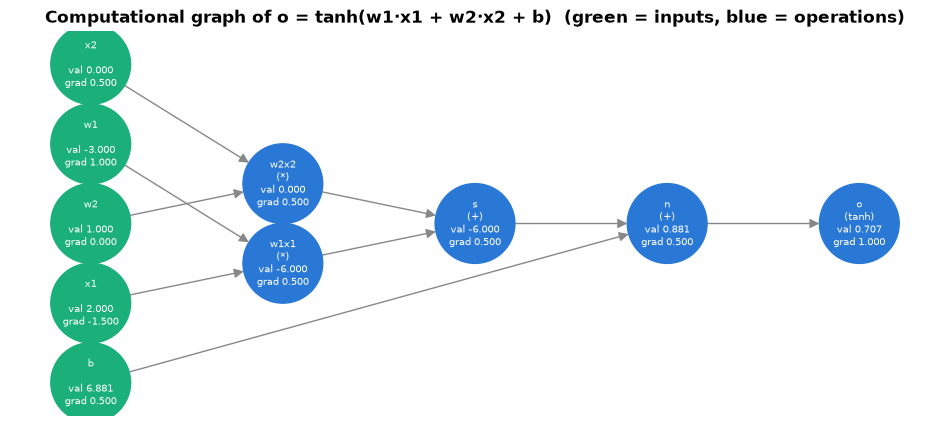

In [7]:
def draw_graph(root, ax, title):
    """Draw a Value graph left-to-right: inputs on the left, output on the right."""
    G = nx.DiGraph(); nodes, stack = set(), [root]
    while stack:
        v = stack.pop()
        if id(v) in nodes:
            continue
        nodes.add(id(v))
        G.add_node(id(v), obj=v)
        for c in v._prev:
            G.add_edge(id(c), id(v)); stack.append(c)
    for layer, ids in enumerate(nx.topological_generations(G)):
        for i in ids:
            G.nodes[i]["layer"] = layer
    pos = nx.multipartite_layout(G, subset_key="layer")
    labels = {i: f"{G.nodes[i]['obj'].label or G.nodes[i]['obj']._op}\n{G.nodes[i]['obj']._op and '(' + G.nodes[i]['obj']._op + ')'}"
                 f"\nval {G.nodes[i]['obj'].data:.3f}\ngrad {G.nodes[i]['obj'].grad:.3f}" for i in G}
    colors = [PALETTE[2] if not G.nodes[i]["obj"]._prev else PALETTE[0] for i in G]
    nx.draw(G, pos, ax=ax, labels=labels, node_color=colors, node_size=3300, font_size=7.5,
            font_color="white", arrowsize=14, edge_color="#888888")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(o, ax, "Computational graph of o = tanh(w1·x1 + w2·x2 + b)  (green = inputs, blue = operations)")
plt.show()

**What just happened?** The engine computed every partial derivative of $o$ in one backward sweep. With $b$ chosen so that $n = 0.8814$, $o = \tanh(n) = 0.7071$ and $\partial o/\partial n = 1 - o^2 = 0.5$. Then the `+` nodes pass 0.5 unchanged, and each `*` node swaps its inputs: $\partial o/\partial w_1 = 0.5 \cdot x_1 = 1$, $\partial o/\partial x_1 = 0.5 \cdot w_1 = -1.5$, and $\partial o/\partial w_2 = 0.5 \cdot x_2 = 0$ (since $x_2 = 0$). The drawing shows the value and gradient stored on every node.

Now the real test: compare with PyTorch on several functions that reuse variables and mix operations.

In [8]:
test_functions = {
    "tanh(ab + c)·a": lambda a, b, c: (a * b + c).tanh() * a,
    "exp(log(a²+b²+1) − c/(1+a²))": lambda a, b, c: ((a**2 + b**2 + 1).log() - c / (1 + a * a)).exp(),
    "relu(ab) + relu(b−c)·a + 3": lambda a, b, c: (a * b).relu() + (b - c).relu() * a + 3,
    "tanh(a³ − 2b + ca)/(2 + b²)": lambda a, b, c: (a * a * a - 2 * b + c * a).tanh() / (2 + b * b),
    "a² + a²b − exp(c+a)·b": lambda a, b, c: a * a + a * a * b - (c + a).exp() * b,
}
rows = []
for name, fn in test_functions.items():
    worst = 0.0
    for trial in range(50):
        p = rng.normal(size=3)
        vals = [Value(v) for v in p]; out = fn(*vals); out.backward()
        ts = [torch.tensor(v, requires_grad=True) for v in p]; out_t = fn(*ts); out_t.backward()
        assert abs(out.data - out_t.item()) < 1e-12
        worst = max(worst, max(abs(v.grad - t.grad.item()) for v, t in zip(vals, ts)))
    rows.append({"function": name, "random points": 50, "max |our grad − torch grad|": worst})
df_val = pd.DataFrame(rows); assert (df_val.iloc[:, 2] < 1e-10).all()
df_val.style.format({"max |our grad − torch grad|": "{:.1e}"})

,function,random points,max |our grad − torch grad|
0,tanh(ab + c)·a,50,3.3e-16
1,exp(log(a²+b²+1) − c/(1+a²)),50,2.7e-15
2,relu(ab) + relu(b−c)·a + 3,50,0.0e+00
3,tanh(a³ − 2b + ca)/(2 + b²),50,2.2e-16
4,a² + a²b − exp(c+a)·b,50,0.0e+00


In [9]:
# ⚠️ Why gradients must be ACCUMULATED: the same variable used twice
class OverwritingValue(Value):
    """A deliberately buggy engine: '=' instead of '+=' in multiplication."""
    def __mul__(self, other):
        other = other if isinstance(other, OverwritingValue) else OverwritingValue(other)
        out = OverwritingValue(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad = other.data * out.grad          # BUG: overwrites instead of accumulating
            other.grad = self.data * out.grad
        out._backward = _backward
        return out

for cls in (Value, OverwritingValue):
    xv = cls(3.0); yv = xv * xv; yv.backward()
    print(f"{cls.__name__:16s}: d(x·x)/dx at x=3 = {xv.grad}   (correct answer 2x = 6)")

Value           : d(x·x)/dx at x=3 = 6.0   (correct answer 2x = 6)
OverwritingValue: d(x·x)/dx at x=3 = 3.0   (correct answer 2x = 6)


**What just happened?** Across 250 random evaluations of five functions (with reused variables, divisions, `exp`, `log`, `tanh` and `relu`), our gradients match PyTorch's to round-off. The buggy engine shows why accumulation matters: in $x \cdot x$ both inputs are the same node, so the second assignment overwrote the first and the gradient came out as 3 instead of 6.

**Complexity.** Forward pass: $O(\text{number of operations})$. Backward pass: the same order, each node visited once (**the "cheap gradient principle": the gradient costs a small constant multiple, typically at most about 4 to 5, of the function evaluation, whatever the number of inputs**). Memory: every intermediate value is kept until the backward pass, $O(\text{number of operations})$, which is the real price of reverse mode.

> 🎓 **Exam / interview tip.** "Implement backprop for a tiny graph" or "why do we zero gradients in PyTorch?" Answer to the second: `.grad` *accumulates* across `backward()` calls (by design, the same `+=` as above), so you call `optimizer.zero_grad()` before each step.

---
## 7. A vectorised `Tensor` engine with broadcasting

> **In plain English:** the same idea as the scalar engine, but each node holds a whole array, so one node can be a full matrix multiplication; the only new trick is undoing broadcasting on the way back.

Scalar nodes are far too slow for real networks. A tensor engine uses the matrix identities from Section 3 as the local backward rules:

| Operation | Forward | Backward (given $\bar C = \partial L/\partial C$) |
|---|---|---|
| matmul $C = AB$ | $(m{\times}k)(k{\times}n)$ | $\bar A = \bar C B^\top$, $\bar B = A^\top \bar C$ |
| add $C = A + B$ (broadcast) | elementwise | $\bar A = \text{unbroadcast}(\bar C)$, likewise $\bar B$ |
| multiply $C = A \odot B$ | elementwise | $\bar A = \text{unbroadcast}(\bar C \odot B)$ |
| sum over an axis | reduce | broadcast $\bar C$ back to $A$'s shape |
| ReLU | $\max(A, 0)$ | $\bar A = \bar C \odot [A > 0]$ |
| softmax + cross-entropy (fused, mean over $N$ rows) | $\frac1N\sum_i(\operatorname{logsumexp}(z_i) - z_{i,y_i})$ | $\bar Z = (\operatorname{softmax}(Z) - Y)/N$ (identity 8) |

Note the shape rule for matmul: $\bar A = \bar C B^\top$ has shape $(m{\times}n)(n{\times}k) = m{\times}k$, the shape of $A$. ✓

**Broadcasting rule for gradients.** If a bias $b$ of shape `(4,)` was broadcast to `(3, 4)` in the forward pass, it was effectively *copied* to 3 rows. Each copy contributes to the loss, so in the backward pass we **sum** the incoming gradient over the broadcast dimensions to get back to shape `(4,)`.

In [10]:
def unbroadcast(grad, shape):
    """Sum `grad` down to `shape`, undoing NumPy broadcasting."""
    while grad.ndim > len(shape):                      # dimensions that were added on the left
        grad = grad.sum(axis=0)
    for i, s in enumerate(shape):                      # dimensions that were stretched from size 1
        if s == 1 and grad.shape[i] != 1:
            grad = grad.sum(axis=i, keepdims=True)
    return grad

class Tensor:
    """Minimal reverse-mode autodiff on NumPy arrays."""
    def __init__(self, data, _children=(), _op=""):
        self.data = np.asarray(data, dtype=float)
        self.grad = np.zeros_like(self.data)
        self._prev, self._op = tuple(_children), _op
        self._backward = lambda: None

    @staticmethod
    def wrap(x):
        return x if isinstance(x, Tensor) else Tensor(x)

    def __add__(self, other):
        other = Tensor.wrap(other); out = Tensor(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += unbroadcast(out.grad, self.data.shape)
            other.grad += unbroadcast(out.grad, other.data.shape)
        out._backward = _backward; return out

    def __mul__(self, other):
        other = Tensor.wrap(other); out = Tensor(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += unbroadcast(out.grad * other.data, self.data.shape)
            other.grad += unbroadcast(out.grad * self.data, other.data.shape)
        out._backward = _backward; return out

    def __matmul__(self, other):
        other = Tensor.wrap(other); out = Tensor(self.data @ other.data, (self, other), "@")
        def _backward():
            self.grad += out.grad @ other.data.T        # (m x n)(n x k) -> m x k
            other.grad += self.data.T @ out.grad        # (k x m)(m x n) -> k x n
        out._backward = _backward; return out

    def sum(self, axis=None, keepdims=False):
        out = Tensor(self.data.sum(axis=axis, keepdims=keepdims), (self,), "sum")
        def _backward():
            g = out.grad
            if axis is not None and not keepdims:
                g = np.expand_dims(g, axis)
            self.grad += np.broadcast_to(g, self.data.shape)   # every summed element gets the same grad
        out._backward = _backward; return out

    def mean(self):
        return self.sum() * (1.0 / self.data.size)

    def relu(self):
        out = Tensor(np.maximum(self.data, 0), (self,), "relu")
        def _backward():
            self.grad += out.grad * (self.data > 0)
        out._backward = _backward; return out

    def exp(self):
        out = Tensor(np.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.grad * out.data
        out._backward = _backward; return out

    def log(self):
        out = Tensor(np.log(self.data), (self,), "log")
        def _backward():
            self.grad += out.grad / self.data
        out._backward = _backward; return out

    def cross_entropy(self, labels):
        """Mean softmax cross-entropy of logits (N x C) against integer labels (N,). Fused and stable."""
        Z = self.data; N = Z.shape[0]
        Zs = Z - Z.max(axis=1, keepdims=True)                      # shift for stability (log-sum-exp trick)
        log_probs = Zs - np.log(np.exp(Zs).sum(axis=1, keepdims=True))
        out = Tensor(-log_probs[np.arange(N), labels].mean(), (self,), "xent")
        def _backward():
            G = np.exp(log_probs); G[np.arange(N), labels] -= 1      # softmax - one_hot
            self.grad += out.grad * G / N
        out._backward = _backward; return out

    def __neg__(self): return self * -1.0
    def __sub__(self, other): return self + (-Tensor.wrap(other))
    __radd__ = __add__
    __rmul__ = __mul__

    def backward(self):
        topo, visited = [], set()
        def build(v):
            if id(v) not in visited:
                visited.add(id(v))
                for c in v._prev:
                    build(c)
                topo.append(v)
        build(self)
        for v in topo:
            v.grad = np.zeros_like(v.data)
        self.grad = np.ones_like(self.data)
        for v in reversed(topo):
            v._backward()

def check_op(name, build_loss, *shapes):
    """Gradient-check a Tensor expression against central differences for every input."""
    arrays = [rng.normal(size=s) for s in shapes]
    ts = [Tensor(a) for a in arrays]; build_loss(*ts).backward()
    errs = []
    for k in range(len(arrays)):
        def f(arr, k=k):
            args = [Tensor(arr if j == k else arrays[j]) for j in range(len(arrays))]
            return float(build_loss(*args).data)
        errs.append(rel_err(ts[k].grad, numerical_grad(f, arrays[k])))
    return {"operation": name, "input shapes": " , ".join(map(str, shapes)), "max relative error": max(errs)}

labels_demo = np.array([0, 2, 1, 2, 0])
rows = [
    check_op("add with broadcasting (3,4)+(4,)", lambda A, b: ((A + b) * (A + b)).sum(), (3, 4), (4,)),
    check_op("multiply with broadcasting (3,1)*(1,4)", lambda A, B: (A * B).exp().sum(), (3, 1), (1, 4)),
    check_op("matmul (5,3)@(3,2)", lambda A, B: ((A @ B) * (A @ B)).sum(), (5, 3), (3, 2)),
    check_op("sum over axis 0, then log", lambda A: ((A * A).sum(axis=0) + 1.0).log().sum(), (4, 3)),
    check_op("relu (away from 0)", lambda A: (A.relu() * A).sum(), (6,)),
    check_op("mean", lambda A: (A * A * A).mean(), (2, 5)),
    check_op("softmax cross-entropy (5 x 3 logits)", lambda Z: Z.cross_entropy(labels_demo), (5, 3)),
    check_op("2-layer MLP end-to-end", lambda X, W1, b1, W2: ((X @ W1 + b1).relu() @ W2).cross_entropy(labels_demo),
             (5, 4), (4, 6), (6,), (6, 3)),
]
df_ops = pd.DataFrame(rows)
assert (df_ops["max relative error"] < 1e-6).all()
df_ops.style.format({"max relative error": "{:.1e}"})

,operation,input shapes,max relative error
0,"add with broadcasting (3,4)+(4,)","(3, 4) , (4,)",1.3e-10
1,"multiply with broadcasting (3,1)*(1,4)","(3, 1) , (1, 4)",1.3e-10
2,"matmul (5,3)@(3,2)","(5, 3) , (3, 2)",1.0e-10
3,"sum over axis 0, then log","(4, 3)",2.8e-10
4,relu (away from 0),"(6,)",6.7e-11
5,mean,"(2, 5)",1.3e-10
6,softmax cross-entropy (5 x 3 logits),"(5, 3)",5.5e-10
7,2-layer MLP end-to-end,"(5, 4) , (4, 6) , (6,) , (6, 3)",7.8e-10


**What just happened?** Every operation, including both broadcasting cases, `sum` over an axis, the fused cross-entropy and a complete 2-layer network, passes the gradient check with relative errors around $10^{-9}$ or smaller. The broadcasting rows are the ones a home-made engine most often gets wrong: without `unbroadcast`, the bias gradient would have shape `(3, 4)` instead of `(4,)`.

> ⚠️ **Common mistake.** Testing `relu` exactly at 0 (or with random inputs that land within $h$ of 0): the function has a kink there, so the central difference averages the two one-sided slopes and reports 0.5 while the engine (correctly, by convention) reports 0 or 1. Gradient-check smooth points, or nudge inputs away from kinks.

---
## 8. Gradient checking done properly

> **In plain English:** the nudge test is only trustworthy if you use enough decimal places, a sensible nudge size, and avoid sharp corners.

Three practical rules, each demonstrated below:
1. **Use float64.** In float32, round-off in $f(x \pm h)$ is about $10^{-7}|f|$, so even a correct gradient shows relative errors of $10^{-3}$ to $10^{-2}$.
2. **Use a relative error**, not an absolute one: an absolute difference of $10^{-4}$ is excellent if gradients are around $10^{3}$ and terrible if they are around $10^{-5}$.
3. **Beware kinks** (ReLU, max, absolute value, hinge loss) within $h$ of the test point.

| Relative error (float64) | Verdict |
|---|---|
| $< 10^{-7}$ | correct |
| $10^{-7}$ to $10^{-4}$ | probably fine for kinked functions; investigate for smooth ones |
| $> 10^{-3}$ | almost certainly a bug |

In [11]:
Xc = rng.normal(size=(8, 4)); Wc = rng.normal(size=(4, 3)); lab = rng.integers(0, 3, size=8)

def loss_np(W, dtype):
    Z = (Xc.astype(dtype) @ W.astype(dtype))
    Z = Z - Z.max(axis=1, keepdims=True)
    return float(-(Z[np.arange(8), lab] - np.log(np.exp(Z).sum(axis=1))).mean())

Wt_ = Tensor(Wc); (Tensor(Xc) @ Wt_).cross_entropy(lab).backward()
rows = []
for dtype, h in [(np.float64, 1e-6), (np.float32, 1e-6), (np.float32, 1e-3)]:
    g_n = numerical_grad(lambda W: loss_np(W, dtype), Wc, h=h)
    rows.append({"dtype": dtype.__name__, "step h": h, "relative error vs engine": rel_err(Wt_.grad, g_n)})

# A kink: relu(x) * 3 at x = 2e-7 (just right of the kink) with a step h = 1e-6 that crosses it
x_kink = np.array([2e-7])
eng = Tensor(x_kink.copy()); (eng.relu() * 3.0).sum().backward()
num = numerical_grad(lambda v: float(np.maximum(v, 0).sum() * 3.0), x_kink, h=1e-6)
rows.append({"dtype": "float64, ReLU kink", "step h": 1e-6, "relative error vs engine": rel_err(eng.grad, num)})
print(f"at the kink: engine says {eng.grad[0]:.2f}, central difference says {num[0]:.2f}")
pd.DataFrame(rows).style.format({"relative error vs engine": "{:.1e}", "step h": "{:.0e}"})

at the kink: engine says 3.00, central difference says 1.80


,dtype,step h,relative error vs engine
0,float64,1e-06,1.3e-10
1,float32,1e-06,1.1e-01
2,float32,1e-03,8.2e-05
3,"float64, ReLU kink",1e-06,2.5e-01


**What just happened?** The same correct gradient looks perfect in float64 (relative error about $10^{-10}$) but "wrong" in float32 with a small step (round-off dominates) and only mediocre with a larger float32 step. At the ReLU kink, the central difference straddles the corner and returns about 1.8 instead of 3: a false alarm, not a bug. Rule: **check gradients in float64, at smooth points, with relative error.**

---
## 9. Training logistic regression and an MLP with our engine

> **In plain English:** with gradients available automatically, training is just "compute loss, backpropagate, step downhill", repeated.

**Gradient descent:** $\theta \leftarrow \theta - \eta \nabla_\theta L$. We train two models with full-batch gradient descent:
1. **Logistic regression** written as a linear layer + 2-class softmax cross-entropy (equivalent to the sigmoid form), on a linearly separable-ish dataset.
2. A **2-layer MLP** $2 \to 32 \to 2$ with ReLU, on the "two moons" dataset, which a linear model cannot separate.

Before training, we confirm that our engine's gradients equal PyTorch's for the *same* weights.

In [12]:
from sklearn.datasets import make_classification, make_moons
import torch.nn.functional as F

# --- Gradient comparison with PyTorch on the MLP, same initial weights ---
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=0)
init = {"W1": rng.normal(0, 1, (2, 32)), "b1": np.zeros(32),
        "W2": rng.normal(0, 1 / math.sqrt(32), (32, 2)), "b2": np.zeros(2)}

def mlp_loss(params, X, y):
    h = (Tensor(X) @ params["W1"] + params["b1"]).relu()
    return (h @ params["W2"] + params["b2"]).cross_entropy(y)

P = {k: Tensor(v.copy()) for k, v in init.items()}
mlp_loss(P, Xm, ym).backward()
Pt = {k: torch.tensor(v.copy(), requires_grad=True) for k, v in init.items()}
logits_t = torch.relu(torch.tensor(Xm) @ Pt["W1"] + Pt["b1"]) @ Pt["W2"] + Pt["b2"]
F.cross_entropy(logits_t, torch.tensor(ym)).backward()
for k in init:
    print(f"{k:3s} grad shape {str(P[k].grad.shape):8s} max |ours − torch| = {np.abs(P[k].grad - Pt[k].grad.numpy()).max():.1e}")

W1  grad shape (2, 32)  max |ours − torch| = 2.8e-17
b1  grad shape (32,)    max |ours − torch| = 5.6e-17
W2  grad shape (32, 2)  max |ours − torch| = 1.1e-16
b2  grad shape (2,)     max |ours − torch| = 2.1e-17


logistic regression, separable data : accuracy 0.997
logistic regression, moons          : accuracy 0.847
2-layer MLP, moons                  : accuracy 0.983  (1,500 steps in 0.9 s)


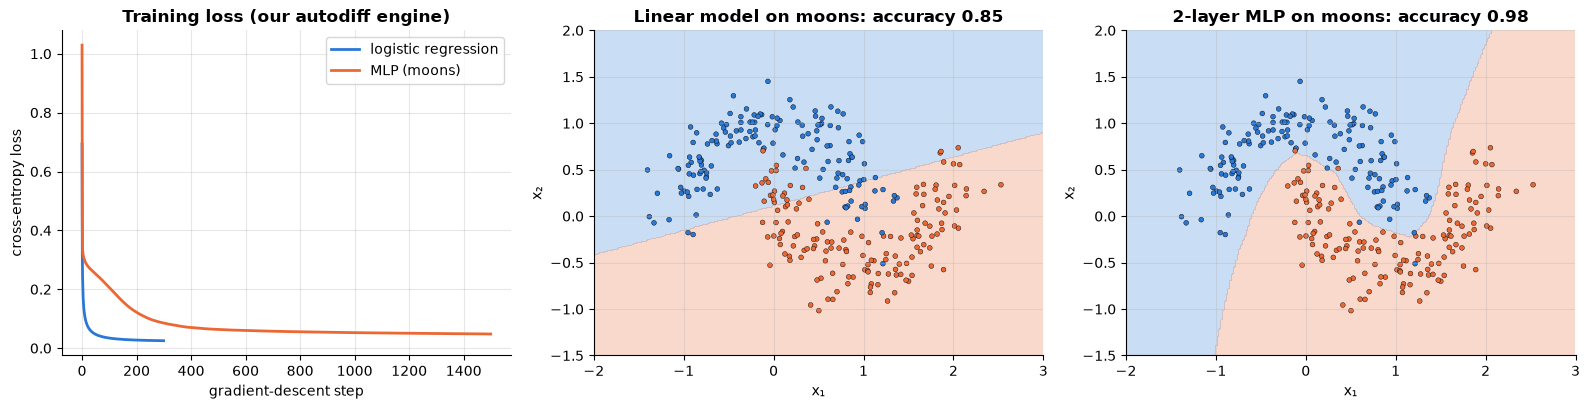

In [13]:
def train(params, X, y, lr, steps):
    history = []
    for step in range(steps):
        loss = mlp_loss(params, X, y) if "W1" in params else \
               (Tensor(X) @ params["W"] + params["b"]).cross_entropy(y)
        loss.backward()                                   # fills every param.grad
        for p in params.values():
            p.data -= lr * p.grad                         # gradient-descent step
        history.append(float(loss.data))
    return history

def predict(params, X):
    if "W1" in params:
        h = np.maximum(X @ params["W1"].data + params["b1"].data, 0)
        return (h @ params["W2"].data + params["b2"].data).argmax(1)
    return (X @ params["W"].data + params["b"].data).argmax(1)

# 1. Logistic regression on a nearly linearly separable problem
Xl, yl = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.5, random_state=3)
logreg = {"W": Tensor(np.zeros((2, 2))), "b": Tensor(np.zeros(2))}
hist_lr = train(logreg, Xl, yl, lr=0.5, steps=300)
# ... and the same linear model on the moons, for comparison
lin_moons = {"W": Tensor(np.zeros((2, 2))), "b": Tensor(np.zeros(2))}
train(lin_moons, Xm, ym, lr=0.5, steps=300)
# 2. The MLP on the moons
mlp = {k: Tensor(v.copy()) for k, v in init.items()}
t0 = time.perf_counter(); hist_mlp = train(mlp, Xm, ym, lr=0.5, steps=1500); t_train = time.perf_counter() - t0

acc = lambda p, X, y: (predict(p, X) == y).mean()
print(f"logistic regression, separable data : accuracy {acc(logreg, Xl, yl):.3f}")
print(f"logistic regression, moons          : accuracy {acc(lin_moons, Xm, ym):.3f}")
print(f"2-layer MLP, moons                  : accuracy {acc(mlp, Xm, ym):.3f}  (1,500 steps in {t_train:.1f} s)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(hist_lr, label="logistic regression"); axes[0].plot(hist_mlp, label="MLP (moons)")
axes[0].set_xlabel("gradient-descent step"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
axes[0].set_title("Training loss (our autodiff engine)")
gx, gy = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.5, 2, 250)); grid = np.c_[gx.ravel(), gy.ravel()]
for ax, params, title in [(axes[1], lin_moons, "Linear model on moons"), (axes[2], mlp, "2-layer MLP on moons")]:
    ax.contourf(gx, gy, predict(params, grid).reshape(gx.shape), alpha=0.25, levels=[-0.5, 0.5, 1.5],
                colors=[PALETTE[0], PALETTE[1]])
    ax.scatter(Xm[:, 0], Xm[:, 1], c=[PALETTE[0] if t == 0 else PALETTE[1] for t in ym], s=12, edgecolor="k", lw=0.3)
    ax.set_title(f"{title}: accuracy {acc(params, Xm, ym):.2f}"); ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
plt.tight_layout(); plt.show()

**What just happened?** At identical weights, our engine's gradients for all four parameter tensors agree with PyTorch's to about $10^{-16}$. Training then works exactly like a framework: logistic regression reaches high accuracy on the separable data, a linear model on the moons is stuck with a straight boundary, and the MLP learns the curved boundary. About 70 lines of NumPy are enough for a working deep-learning engine; frameworks add GPU kernels, many more operations, memory management and compilation.

---
## 10. Higher-order derivatives: Hessian-vector products and Newton's method

> **In plain English:** the gradient tells you which way is downhill; the Hessian tells you how the slope bends, and using it lets you jump almost straight to the bottom of a bowl.

The **Hessian** $H = \nabla^2 L$ has $n^2$ entries, far too many to store for a big model. But the **Hessian-vector product** $Hv$ can be computed without ever forming $H$:

$$Hv = \nabla_\theta\big(\nabla_\theta L(\theta)^\top v\big),$$

which is "differentiate the gradient (dotted with $v$) again". In PyTorch this is **double backward**: compute the gradient with `create_graph=True` so that the gradient computation is itself recorded, then backpropagate through it. Cost: about twice a gradient.

**Newton's method** steps by $\Delta = -H^{-1}\nabla L$, which converges quadratically near the minimum (compare Newton's root finding in [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb)). Instead of inverting $H$, **Hessian-free (Newton-CG)** methods solve $H\Delta = -\nabla L$ with **conjugate gradient** ([`10_numerical_linear_algebra.ipynb`](10_numerical_linear_algebra.ipynb)), which needs only Hessian-vector products.

For $L_2$-regularised logistic regression, $L(w) = \frac1N\sum_i \text{BCE}(\sigma(x_i^\top w), y_i) + \frac\lambda2\|w\|^2$, the exact Hessian is $H = \frac1N X^\top \operatorname{diag}(p_i(1 - p_i))X + \lambda I$, which we use to check the HVP.

HVP by double backward vs exact formula: max diff 5.7e-14
torch.autograd.functional.hessian vs exact formula: max diff 2.8e-14


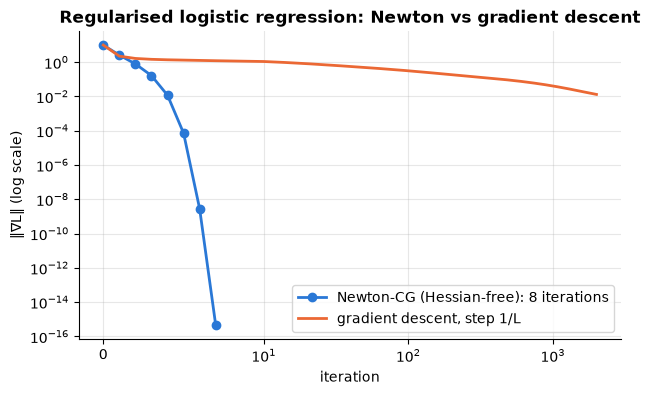

Newton gradient norms: ['1.0e+01', '2.6e+00', '7.9e-01', '1.6e-01', '1.2e-02', '7.3e-05', '2.8e-09', '4.6e-16']
gradient descent after 2,000 iterations: ‖∇L‖ = 1.3e-02


In [14]:
Xn, yn = make_classification(n_samples=500, n_features=10, n_informative=6, random_state=1)
Xn = Xn * np.logspace(0, 1, 10)                           # features on scales from 1 to 10, like unscaled real data
Xn = np.c_[Xn, np.ones(len(Xn))]                           # a column of ones = bias term
Xt_, yt_ = torch.tensor(Xn), torch.tensor(yn, dtype=torch.float64)
lam_n = 1e-3

def logreg_loss(w):
    return F.binary_cross_entropy_with_logits(Xt_ @ w, yt_) + 0.5 * lam_n * (w @ w)

def grad_and_hvp(w, v):
    w = w.detach().requires_grad_(True)
    g = torch.autograd.grad(logreg_loss(w), w, create_graph=True)[0]   # keep the graph of the gradient
    hv = torch.autograd.grad(g @ v, w)[0]                               # differentiate again: H v
    return g.detach(), hv

w0 = torch.tensor(rng.normal(size=11) * 0.1); v0 = torch.tensor(rng.normal(size=11))
g0, hv0 = grad_and_hvp(w0, v0)
p0 = torch.sigmoid(Xt_ @ w0)
H_exact = Xt_.T @ (Xt_ * (p0 * (1 - p0))[:, None]) / len(yn) + lam_n * torch.eye(11)
H_torch = torch.autograd.functional.hessian(logreg_loss, w0)
print(f"HVP by double backward vs exact formula: max diff {torch.abs(hv0 - H_exact @ v0).max():.1e}")
print(f"torch.autograd.functional.hessian vs exact formula: max diff {torch.abs(H_torch - H_exact).max():.1e}")

def cg_solve(matvec, b, iters=50, tol=1e-12):
    x = torch.zeros_like(b); r = b.clone(); p = r.clone(); rr = r @ r
    for _ in range(iters):
        Ap = matvec(p); alpha = rr / (p @ Ap)
        x += alpha * p; r -= alpha * Ap
        if torch.sqrt(r @ r) < tol: break
        rr_new = r @ r; p = r + (rr_new / rr) * p; rr = rr_new
    return x

w = torch.zeros(11); newton_hist = []
for it in range(10):
    g, _ = grad_and_hvp(w, torch.zeros(11))
    newton_hist.append(g.norm().item())
    if newton_hist[-1] < 1e-12: break
    step = cg_solve(lambda v: grad_and_hvp(w, v)[1], -g)     # solve H step = -g using only HVPs
    w = w + step

w_gd = torch.zeros(11); gd_hist = []
L_smooth = torch.linalg.eigvalsh(Xt_.T @ Xt_ / (4 * len(yn))).max().item() + lam_n   # Lipschitz constant of the gradient
for it in range(2000):
    w_gd = w_gd.detach().requires_grad_(True)
    g = torch.autograd.grad(logreg_loss(w_gd), w_gd)[0]
    gd_hist.append(g.norm().item())
    w_gd = w_gd - g / L_smooth                               # the classic safe step 1/L

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(newton_hist, "o-", label=f"Newton-CG (Hessian-free): {len(newton_hist)} iterations")
ax.semilogy(gd_hist, label="gradient descent, step 1/L")
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("iteration"); ax.set_ylabel("‖∇L‖ (log scale)")
ax.set_title("Regularised logistic regression: Newton vs gradient descent"); ax.legend(); plt.show()
print("Newton gradient norms:", [f"{v:.1e}" for v in newton_hist])
print(f"gradient descent after 2,000 iterations: ‖∇L‖ = {gd_hist[-1]:.1e}")

**What just happened?** The double-backward Hessian-vector product equals the exact Hessian formula times $v$ to round-off, without ever building the Hessian inside the Newton loop. Newton-CG drives the gradient norm from about 10 to round-off level in 8 iterations, and the printed norms show quadratic convergence (near the end the exponent roughly doubles each step). Gradient descent with the safe step $1/L$ is still far from that accuracy after 2,000 iterations, because features on different scales make the problem ill-conditioned: $L$ is set by the steepest direction while progress along the flattest one is slow (the same story as the learning-rate limit in [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb)). Standardising the features would help gradient descent a lot; Newton's method does not care, because it is invariant to rescaling the parameters. The price of Newton is the inner CG loop: each Newton step here used several Hessian-vector products, each about twice the cost of a gradient.

**Complexity.** Gradient: $O(\text{cost of } L)$. Hessian-vector product: about $2\times$ that. Full Hessian: $n$ HVPs, $O(n^2)$ memory, which is why it is never formed for neural networks.

---
## 11. How this connects to modern AI

> **In plain English:** every deep-learning framework is a polished, GPU-accelerated version of the engine you just built.

- **PyTorch** builds the graph dynamically during the forward pass (define-by-run), exactly like our `Value` and `Tensor` classes, and `loss.backward()` runs reverse mode over it. **JAX** exposes the building blocks directly: `jax.jvp`, `jax.vjp`, `jax.grad`, and composes them (`jax.jacfwd`, `jax.jacrev`, `jax.hessian`); PyTorch offers the same through `torch.func`, which we used in Section 4.
- **Memory is the bottleneck of reverse mode.** Storing every activation for the backward pass is what limits batch size and context length when training LLMs. **Gradient checkpointing** (`torch.utils.checkpoint`) stores only some activations and recomputes the rest during the backward pass: about one extra forward pass in exchange for roughly $O(\sqrt{\text{layers}})$ memory.
- **Mixed precision.** Training in float16/bfloat16 makes small gradients underflow; *loss scaling* multiplies the loss before `backward()` and divides the gradients afterwards. Section 8 shows why gradient *checks* must still be done in float64.
- **Custom gradients.** Fused kernels such as FlashAttention and fused cross-entropy define their own backward rule (like our `cross_entropy`) for speed and stability; `torch.autograd.Function` is how you write one.
- **Second-order information.** Hessian-vector products power Newton-CG and K-FAC style optimisers, influence functions, and measurements of "sharpness" (the top Hessian eigenvalue, via power iteration on HVPs), which connects to the learning-rate stability limit $\eta < 2/\lambda_{\max}$ from [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb).
- **Differentiable programming beyond neural networks:** differentiable physics simulators, Neural ODEs ([`05_Deep_Learning/10_neural_ode.ipynb`](../05_Deep_Learning/10_neural_ode.ipynb), which use the adjoint method, a continuous-time VJP), and differentiable rendering.

Optimisers that use these gradients are covered in [`06_optimization.ipynb`](06_optimization.ipynb) and [`05_Deep_Learning/02_optimizers.ipynb`](../05_Deep_Learning/02_optimizers.ipynb).

---
## 12. Recap

- **Shapes first:** the gradient of a scalar has the shape of its variable; Jacobians are $m \times n$ (numerator layout); chain rule $J_{g \circ f} = J_g J_f$, and for a scalar loss $\nabla_x L = J_f^\top \nabla_f L$.
- **Differentials** give fast derivations: $df = (\nabla f)^\top dx$ or $\operatorname{tr}((\nabla_X f)^\top dX)$.
- Key results: $\nabla(x^\top Ax) = (A + A^\top)x$, $\nabla\|Ax - b\|^2 = 2A^\top(Ax - b)$, $\nabla_A\operatorname{tr}(AB) = B^\top$, $\nabla\log\det X = X^{-\top}$, softmax Jacobian $\operatorname{diag}(s) - ss^\top$, and **softmax + cross-entropy gradient $= s - y$**.
- **Forward mode** (dual numbers, JVPs) costs one pass per *input*; **reverse mode** (backprop, VJPs) costs one pass per *output* but stores intermediates. A scalar loss with many parameters needs reverse mode.
- A reverse-mode engine = graph + topological sort + local chain-rule rules + **gradient accumulation**; a tensor engine adds matrix rules and **unbroadcasting**.
- **Gradient checks:** central differences, float64, relative error, avoid kinks.
- **Hessian-vector products** by double backward enable Newton-CG without forming the Hessian.

---
## Practice problems

**1. (Easy)** Let $f(W) = \|Wx\|^2$ with $W \in \mathbb{R}^{m \times n}$, $x \in \mathbb{R}^n$. What shape is $\nabla_W f$, and what is it? Check numerically.

<details><summary>Show solution</summary>

```python
import numpy as np
rng = np.random.default_rng(0)
W, x = rng.normal(size=(3, 4)), rng.normal(size=4)
analytic = 2 * np.outer(W @ x, x)                      # shape (3, 4), same as W
f = lambda M: np.sum((M @ x) ** 2)
h = 1e-6; numeric = np.zeros_like(W)
for i in range(3):
    for j in range(4):
        E = np.zeros_like(W); E[i, j] = h
        numeric[i, j] = (f(W + E) - f(W - E)) / (2 * h)
print(analytic.shape, np.abs(analytic - numeric).max())
assert np.allclose(analytic, numeric, atol=1e-6)
```
With $r = Wx$: $df = 2r^\top dr = 2r^\top (dW)\,x = \operatorname{tr}(2\,x r^\top dW)$, so $\nabla_W f = (2xr^\top)^\top = 2(Wx)x^\top$: an outer product with the shape of $W$ ($m \times n$). This is exactly the weight gradient of a linear layer: (output gradient) × (input)ᵀ.

</details>

**2. (Easy, conceptual)** What is the Jacobian of the elementwise sigmoid $\sigma: \mathbb{R}^n \to \mathbb{R}^n$, and why does no autodiff engine ever build it?

<details><summary>Show solution</summary>

The sigmoid acts elementwise, so $\partial \sigma(z)_i/\partial z_j = 0$ for $i \ne j$ and the Jacobian is $\operatorname{diag}(\sigma(z) \odot (1 - \sigma(z)))$. A VJP with it is just an elementwise product: $u^\top J = u \odot \sigma(z) \odot (1 - \sigma(z))$, costing $O(n)$. Building the $n \times n$ diagonal matrix would cost $O(n^2)$ memory and time for nothing. Every elementwise operation (ReLU, tanh, GELU, dropout masks) is handled this way in real engines.

</details>

**3. (Medium, coding)** Add a `sigmoid` method to the `Value` class and check its gradient against PyTorch.

<details><summary>Show solution</summary>

```python
def sigmoid(self):
    s = 1.0 / (1.0 + math.exp(-self.data))
    out = Value(s, (self,), "sigmoid")
    def _backward():
        self.grad += s * (1 - s) * out.grad
    out._backward = _backward
    return out
Value.sigmoid = sigmoid

for z in [-3.0, 0.0, 0.7, 4.0]:
    v = Value(z); y = (v.sigmoid() * v).tanh(); y.backward()
    t = torch.tensor(z, requires_grad=True); yt = torch.tanh(torch.sigmoid(t) * t); yt.backward()
    assert abs(v.grad - t.grad.item()) < 1e-12
    print(z, round(v.grad, 10), round(t.grad.item(), 10))
```
The local derivative is $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, and we reuse the stored forward value $s$, a typical trick that saves recomputation.

</details>

**4. (Medium, coding)** Derive the gradients of the mean-squared error of linear regression with a bias, $L = \frac1N\|Xw + b - y\|^2$, and check them with the `Tensor` engine. Why is the bias gradient a sum?

<details><summary>Show solution</summary>

```python
Xr = rng.normal(size=(50, 3)); yr = Xr @ np.array([1.0, -2.0, 0.5]) + 0.3 + 0.1 * rng.normal(size=50)
w_r, b_r = Tensor(rng.normal(size=(3, 1))), Tensor(np.zeros(1))
resid = Tensor(Xr) @ w_r + b_r - yr[:, None]          # (50, 1); b is broadcast over the rows
loss = (resid * resid).mean(); loss.backward()
r = Xr @ w_r.data + b_r.data - yr[:, None]
grad_w = 2 / 50 * Xr.T @ r                             # (3, 1)
grad_b = 2 / 50 * r.sum(axis=0)                        # (1,)  -- the broadcast dimension is summed
assert np.allclose(w_r.grad, grad_w) and np.allclose(b_r.grad, grad_b)
print(w_r.grad.ravel(), b_r.grad)
```
$L = \frac1N\|Xw + b\mathbf 1 - y\|^2$ gives $\nabla_w L = \frac2N X^\top r$ and $\nabla_b L = \frac2N \mathbf 1^\top r$ (the sum of residuals), with $r = Xw + b\mathbf 1 - y$. The bias gradient is a sum because $b$ was broadcast to every row, which is exactly what `unbroadcast` does.

</details>

**5. (Medium, coding)** Use *nested* dual numbers to compute second derivatives. Check $f''(0.7)$ for the function of Section 5 and $\frac{d^2}{dx^2}x^3$ at $x = 2$.

<details><summary>Show solution</summary>

```python
def second_derivative(f, x):
    # x + eps1 + eps2 + 0*eps1*eps2, written as a Dual whose parts are Duals
    return f(Dual(Dual(x, 1.0), Dual(1.0, 0.0))).b.b

f = lambda t: t * d_sin(t) + d_exp(t ** 2) / (1 + t)
x0, h = 0.7, 1e-4
fd2 = (f(x0 + h) - 2 * f(x0) + f(x0 - h)) / h ** 2
print(second_derivative(f, x0), fd2)
assert abs(second_derivative(f, x0) - fd2) < 1e-5
print(second_derivative(lambda t: t ** 3, 2.0))         # 6 * 2 = 12
assert abs(second_derivative(lambda t: t ** 3, 2.0) - 12.0) < 1e-12
```
Nesting works because every rule in `Dual` and `d_sin`, `d_exp`, ... only uses `+`, `*`, `/` and the same elementary functions, so it applies equally when the parts are themselves `Dual` numbers. The outer tangent of the inner tangent is $f''(x)$. This is "forward-over-forward" differentiation.

</details>

**6. (Hard, conceptual)** A network has $10^6$ parameters and a scalar loss. Compare the cost of forward- and reverse-mode gradients, and state the hidden cost of reverse mode and two ways to reduce it.

<details><summary>Show solution</summary>

With $n = 10^6$ parameters and a scalar loss, forward mode needs $10^6$ passes (one per parameter) while reverse mode needs 1 backward pass costing a small constant multiple of the forward pass. The price of reverse mode is **memory**: all intermediate activations of the forward pass must be stored until the backward pass uses them, so memory grows with depth × batch size × layer width. Remedies: gradient checkpointing (recompute instead of storing), smaller batches with gradient accumulation, activation offloading, and lower precision.

</details>

**7. (Hard, coding)** Compute the Hessian-vector product of the logistic-regression loss by **forward-over-reverse** (`torch.func.jvp` of `torch.func.grad`) and check it against double backward.

<details><summary>Show solution</summary>

```python
from torch.func import grad as fgrad, jvp
w_test = torch.tensor(rng.normal(size=11) * 0.1); v_test = torch.tensor(rng.normal(size=11))
_, hv_fwd_over_rev = jvp(fgrad(logreg_loss), (w_test,), (v_test,))   # JVP of the gradient function
_, hv_double = grad_and_hvp(w_test, v_test)                            # reverse-over-reverse
p = torch.sigmoid(Xt_ @ w_test)
H = Xt_.T @ (Xt_ * (p * (1 - p))[:, None]) / len(yn) + lam_n * torch.eye(11)
assert torch.allclose(hv_fwd_over_rev, H @ v_test) and torch.allclose(hv_double, H @ v_test)
print("forward-over-reverse HVP matches double backward and the exact Hessian")
```
$Hv$ is the directional derivative of the gradient in direction $v$, i.e. a JVP of the function $w \mapsto \nabla L(w)$. Forward-over-reverse is usually the most efficient way to compute it, because it does not need to store a second reverse pass.

</details>

---
## Further reading
- Goodfellow, Bengio and Courville, *Deep Learning* (MIT Press, 2016; free at https://www.deeplearningbook.org): §6.5, back-propagation and other differentiation algorithms.
- Petersen and Pedersen, *The Matrix Cookbook* (free PDF): identities for traces, determinants and matrix derivatives.
- Terence Parr and Jeremy Howard, "The Matrix Calculus You Need For Deep Learning" (2018, arXiv:1802.01528).
- Baydin, Pearlmutter, Radul and Siskind, "Automatic Differentiation in Machine Learning: a Survey", *JMLR* 18(153), 2018.
- Griewank and Walther, *Evaluating Derivatives: Principles and Techniques of Algorithmic Differentiation*, 2nd ed. (SIAM, 2008), the standard reference on AD.
- Free: Andrej Karpathy's *micrograd* repository and lecture "The spelled-out intro to neural networks and backpropagation" (https://github.com/karpathy/micrograd); MIT OCW 18.S096 *Matrix Calculus for Machine Learning and Beyond* (Edelman and Johnson).

## Next notebook
Continue with [`12_convex_optimization_and_duality.ipynb`](12_convex_optimization_and_duality.ipynb) (convex sets and functions, Lagrange duality, KKT conditions, and solvers), or revisit how these gradients are used by optimisers in [`06_optimization.ipynb`](06_optimization.ipynb).